# 08 Rotation thermometer: Part A (build years only)
Build years = 1999-01-04 to 2020-12-31. **Nothing dated 2021 or later is loaded or computed here** (the file is filtered while reading; checkpoints without a full next-month outcome are dropped and counted).

**This measures labels, not a trading strategy. No trading costs are applied.** An average excess under about 0.2% a month would likely not survive the 0.10%-per-trade cost in practice.

**Reminder on sector baskets:** the number of sector funds changes over time (9, then 10 when XLRE joins in late 2015, then 11 when XLC joins in mid 2018), and XLK, XLY, XLC, XLF and XLRE changed contents in 2016 and 2018 (real estate left XLF for XLRE in Sept 2016; Alphabet and Meta moved from XLK, and Netflix and Disney from XLY, into the new XLC in Sept 2018). The spread across sectors therefore changes slightly with the number of funds.

Rules (only information available at each checkpoint):
- **Thermometer (every trading day):** standard deviation (sample, n-1) across the sector funds that exist that day (a fund counts if it has prices that day and 21 trading days earlier) of their 21-trading-day price changes (adjusted close) ending that day. Sector funds only. High = the sectors are moving very differently from each other.
- **Hot / cool:** the day's thermometer vs the median of the thermometer over the previous 252 trading days (not including that day). Above = hot; otherwise cool.
- **Checkpoints:** the same 21-day grid as notebooks 02-07 (every 21st trading day counted from 1999-01-04), starting at the first one with enough history (21 + 252 days).
- **Outcomes:** from the NEXT day's close over the following 21 trading days: SPY's return; SPY's volatility (annualized standard deviation of the 21 daily returns in that span); the sector spread (standard deviation across sectors of their changes over that span).
- **Mood:** the 06 rules, copied unchanged and checked against `results/06_observations.csv`.
- **Rough 95% ranges:** resample checkpoints with replacement (2,000 draws, fixed seed).

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve()
if not (ROOT / "config.py").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import config
from rotation.data import load_prices, wide
from rotation.returns import daily_returns
pd.set_option("display.width", 220, "display.max_columns", 40, "display.max_rows", 300)
R = config.RESULTS_DIR; R.mkdir(exist_ok=True)
N = 21; DELAY = 1; SPAN = DELAY + N
SECT = config.SECTORS
MOODS = ["calm uptrend", "stormy uptrend", "calm downtrend", "stormy downtrend"]
B = 2000

## 1. Load build years only (SPY and the 11 sector funds; adjusted close)

In [2]:
df = load_prices(symbols=["SPY"] + SECT, fields=["adj_close"], end=config.BUILD_END)
assert df.date.max() <= pd.Timestamp(config.BUILD_END)
P = wide(df, "adj_close")[["SPY"] + SECT]
n = len(P)
assert n == 5536                      # same trading calendar as notebooks 02-07
S = P[SECT]
print(P.index.min().date(), "to", P.index.max().date(), "|", n, "days")

1999-01-04 to 2020-12-31 | 5536 days


## 2. Thermometer, hot/cool label, mood and next-month outcomes at each checkpoint

In [3]:
chg21 = S / S.shift(21) - 1                                     # 21-day price change of each sector fund
n_sect = chg21.notna().sum(axis=1)
therm = chg21.std(axis=1, ddof=1, skipna=True).where(n_sect >= 2)   # spread across the sector funds that exist
med_t = therm.shift(1).rolling(252).median()                    # median over the previous 252 days (excludes today)
hot = therm > med_t

# mood: the 06 rules, unchanged
spy = P["SPY"]; ret = daily_returns(P)
sma200 = spy.rolling(200).mean()
vol21 = ret["SPY"].rolling(21).std()
med252 = vol21.shift(1).rolling(252).median()
uptrend = spy >= sma200
stormy = vol21 > med252

fund_out = S.shift(-SPAN) / S.shift(-DELAY) - 1                # each sector fund, next day's close to 21 days later
sec_avg_out = fund_out.mean(axis=1, skipna=True)
spread_out = fund_out.std(axis=1, ddof=1, skipna=True)
spy_out = spy.shift(-SPAN) / spy.shift(-DELAY) - 1

valid = med_t.notna() & sma200.notna() & med252.notna()
checks = [i for i in range(N, n, N) if valid.iloc[i]]
print("first checkpoint:", P.index[checks[0]].date(), "(position", checks[0], ") | last:", P.index[checks[-1]].date(), "| checkpoints:", len(checks))

rows = []
for i in checks:
    has_out = i + SPAN <= n - 1
    chg = chg21.iloc[i].dropna()
    top = list(chg.nlargest(5).index)
    r = dict(pos=i, date=P.index[i], year=P.index[i].year, thermometer=therm.iloc[i], median_prev252=med_t.iloc[i], n_sectors=int(n_sect.iloc[i]),
             label="hot" if hot.iloc[i] else "cool", trend="uptrend" if uptrend.iloc[i] else "downtrend", storm="stormy" if stormy.iloc[i] else "calm",
             has_outcome=has_out,
             spy_ret=spy_out.iloc[i] if has_out else np.nan,
             spy_vol_ann=ret["SPY"].iloc[i + DELAY + 1: i + SPAN + 1].std() * np.sqrt(252) if has_out else np.nan,
             sector_spread=spread_out.iloc[i] if has_out else np.nan,
             top5=" ".join(top), top5_excess=(fund_out.iloc[i][top].mean() - sec_avg_out.iloc[i]) if has_out else np.nan)
    rows.append(r)
obs = pd.DataFrame(rows)
obs["mood"] = obs.storm + " " + obs.trend
dropped = obs[~obs.has_outcome].date.dt.date.astype(str).tolist()
print("checkpoints without a full next-month outcome inside the build years (dropped from outcome results):", dropped)
print("sector funds used at checkpoints:", obs.n_sectors.value_counts().sort_index().to_dict())

first checkpoint: 2000-02-02 (position 273 ) | last: 2020-12-14 | checkpoints: 251


checkpoints without a full next-month outcome inside the build years (dropped from outcome results): ['2020-12-14']
sector funds used at checkpoints: {9: 189, 10: 33, 11: 29}


## 3. Checks: hand calculation, and agreement with notebooks 06 and 03

In [4]:
# (a) hand check of the thermometer and the next-month spread at one checkpoint, plain loops
i0 = checks[100]; r0 = obs[obs.pos == i0].iloc[0]
vals = []
for s in SECT:
    a, b = S[s].iloc[i0 - 21], S[s].iloc[i0]
    if not (np.isnan(a) or np.isnan(b)): vals.append(b / a - 1)
m_ = sum(vals) / len(vals); sd_h = (sum((v - m_) ** 2 for v in vals) / (len(vals) - 1)) ** 0.5
assert abs(sd_h - r0.thermometer) < 1e-12 and len(vals) == r0.n_sectors
past = []
for j in range(i0 - 252, i0):
    vv = []
    for s in SECT:
        a, b = S[s].iloc[j - 21], S[s].iloc[j]
        if not (np.isnan(a) or np.isnan(b)): vv.append(b / a - 1)
    mm = sum(vv) / len(vv); past.append((sum((v - mm) ** 2 for v in vv) / (len(vv) - 1)) ** 0.5)
assert (r0.label == "hot") == (sd_h > np.median(past))
outs = [S[s].iloc[i0 + SPAN] / S[s].iloc[i0 + DELAY] - 1 for s in SECT if not (np.isnan(S[s].iloc[i0 + SPAN]) or np.isnan(S[s].iloc[i0 + DELAY]))]
mo = sum(outs) / len(outs); sp_h = (sum((v - mo) ** 2 for v in outs) / (len(outs) - 1)) ** 0.5
assert abs(sp_h - r0.sector_spread) < 1e-12
print("hand check passed for", P.index[i0].date(), "| thermometer %.4f vs median of previous 252 days %.4f -> %s | next-month sector spread %.4f" % (sd_h, np.median(past), r0.label, sp_h))

# (b) the mood labels and SPY outcomes must equal notebook 06's file exactly
o6 = pd.read_csv(R / "06_observations.csv", parse_dates=["date"])
m = o6.merge(obs, on="pos", suffixes=("_06", "_08"))
assert len(m) == len(o6) == len(obs), (len(m), len(o6), len(obs))
assert (m.mood_06 == m.mood_08).all() and (m.has_outcome_06 == m.has_outcome_08).all()
assert np.allclose(m.spy_ret_06, m.spy_ret_08, equal_nan=True) and np.allclose(m.spy_vol_ann_06, m.spy_vol_ann_08, equal_nan=True)
print("mood labels, SPY next-month returns and volatilities match results/06_observations.csv for all", len(m), "checkpoints")

# (c) the Top-5 selections must equal notebook 03's trades
t3 = pd.read_csv(R / "03_trades_top5.csv", parse_dates=["rank_date"]).set_index("rank_date")
miss = [d for d in obs.date if d not in t3.index]
assert not miss, miss[:3]
bad = [d for d, f in zip(obs.date, obs.top5) if set(f.split()) != set(t3.loc[d, "funds"].split())]
assert not bad, bad[:3]
print("Top-5 selections match results/03_trades_top5.csv for all", len(obs), "checkpoints")

hand check passed for 2008-06-11 | thermometer 0.0529 vs median of previous 252 days 0.0321 -> hot | next-month sector spread 0.0736
mood labels, SPY next-month returns and volatilities match results/06_observations.csv for all 251 checkpoints
Top-5 selections match results/03_trades_top5.csv for all 251 checkpoints


## 4. Result 1: the thermometer over time, and hot vs cool by year

      checkpoints  hot  cool  hot_share_pct
year                                       
2000           11    8     3           72.7
2001           12    9     3           75.0
2002           12    6     6           50.0
2003           12    4     8           33.3
2004           12    6     6           50.0
2005           12    6     6           50.0
2006           12    7     5           58.3
2007           12    5     7           41.7
2008           12    9     3           75.0
2009           12    6     6           50.0
2010           12    1    11            8.3
2011           12    5     7           41.7
2012           12    4     8           33.3
2013           12    5     7           41.7
2014           12    7     5           58.3
2015           12    8     4           66.7
2016           12    5     7           41.7
2017           12    5     7           41.7
2018           12    9     3           75.0
2019           12    5     7           41.7
2020           12    8     4    


thermometer on checkpoints: median 2.89%, 10th-90th percentile 1.66% to 5.51%, max 10.64% (2008-08-11)


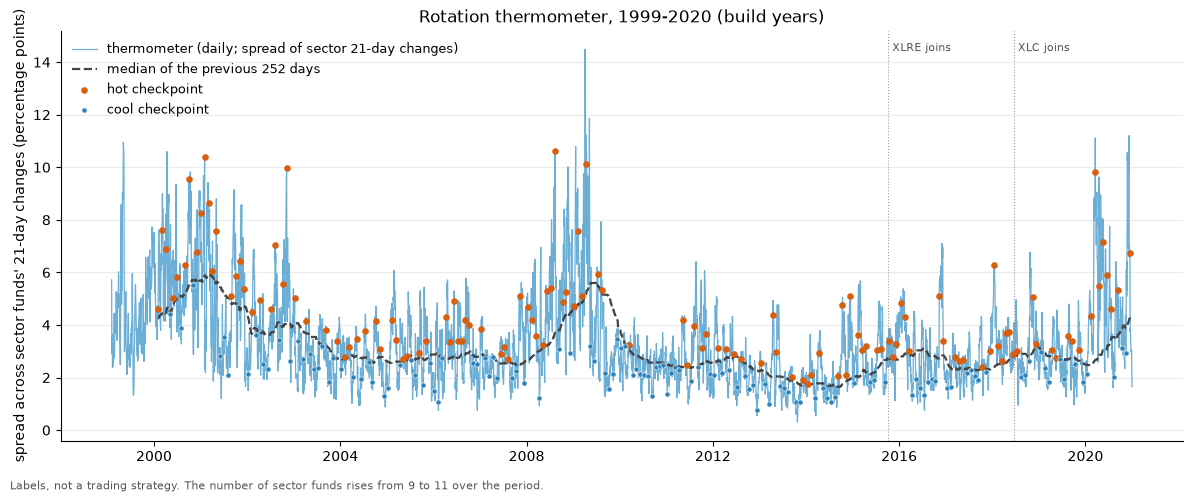

In [5]:
daily = pd.DataFrame({"thermometer": therm, "median_previous_252": med_t, "n_sectors": n_sect, "hot": hot & med_t.notna()})
daily.index.name = "date"
daily.round(5).to_csv(R / "08_thermometer_daily.csv")
by_year = obs.groupby("year").agg(checkpoints=("label", "size"), hot=("label", lambda s: int((s == "hot").sum())))
by_year["cool"] = by_year.checkpoints - by_year.hot
by_year["hot_share_pct"] = by_year.hot / by_year.checkpoints * 100
by_year.loc["All"] = [by_year.checkpoints.sum(), by_year.hot.sum(), by_year.cool.sum(), by_year.hot.sum() / by_year.checkpoints.sum() * 100]
by_year[["checkpoints", "hot", "cool"]] = by_year[["checkpoints", "hot", "cool"]].astype(int)
by_year.round(1).to_csv(R / "08_hot_cool_by_year.csv")
print(by_year.round(1).to_string())
print("\nthermometer on checkpoints: median %.2f%%, 10th-90th percentile %.2f%% to %.2f%%, max %.2f%% (%s)" % (
    obs.thermometer.median() * 100, obs.thermometer.quantile(.1) * 100, obs.thermometer.quantile(.9) * 100, obs.thermometer.max() * 100, obs.loc[obs.thermometer.idxmax(), "date"].date()))

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(therm.index, therm * 100, color="#6baed6", lw=0.9, label="thermometer (daily; spread of sector 21-day changes)")
ax.plot(med_t.index, med_t * 100, color="#444444", lw=1.6, ls="--", label="median of the previous 252 days")
h = obs[obs.label == "hot"]; c_ = obs[obs.label == "cool"]
ax.scatter(h.date, h.thermometer * 100, s=14, color="#d95f0e", zorder=3, label="hot checkpoint")
ax.scatter(c_.date, c_.thermometer * 100, s=14, color="#2b83ba", edgecolor="white", linewidth=0.4, zorder=3, label="cool checkpoint")
for d_, lab in [(pd.Timestamp("2015-10-08"), "XLRE joins"), (pd.Timestamp("2018-06-19"), "XLC joins")]:
    ax.axvline(d_, color="#999999", lw=0.8, ls=":"); ax.text(d_, ax.get_ylim()[1] * 0.97, " " + lab, fontsize=8, color="#555555", va="top")
ax.set_ylabel("spread across sector funds' 21-day changes (percentage points)")
ax.set_title("Rotation thermometer, 1999-2020 (build years)")
for sp in ("top", "right"): ax.spines[sp].set_visible(False)
ax.grid(axis="y", alpha=0.25); ax.legend(frameon=False, loc="upper left", fontsize=9)
fig.text(0.01, 0.01, "Labels, not a trading strategy. The number of sector funds rises from 9 to 11 over the period.", fontsize=8, color="#555555")
fig.tight_layout(rect=(0, 0.03, 1, 1)); fig.savefig(R / "08_thermometer.png", dpi=130); plt.show()

## 5. Result 2: R1, thermometer at the checkpoint vs next month's sector spread; hot/cool stickiness
One observation per checkpoint (those with a full next-month outcome). Rough 95% range resamples checkpoints with replacement.

In [6]:
d = obs[obs.has_outcome].reset_index(drop=True)
K = len(d)
IDX = np.random.default_rng(0).integers(0, K, size=(B, K))
def corr_boot(x, y):
    xs, ys = x[IDX], y[IDX]
    xs = xs - xs.mean(axis=1, keepdims=True); ys = ys - ys.mean(axis=1, keepdims=True)
    return (xs * ys).sum(axis=1) / np.sqrt((xs ** 2).sum(axis=1) * (ys ** 2).sum(axis=1))
x, y = d.thermometer.values, d.sector_spread.values
rho = np.corrcoef(x, y)[0, 1]; bs = corr_boot(x, y)
sp_rho = pd.Series(x).corr(pd.Series(y), method="spearman")
r1 = pd.DataFrame([dict(measure="Pearson correlation: thermometer at checkpoint vs next-month sector spread", value=rho, range95_low=np.percentile(bs, 2.5), range95_high=np.percentile(bs, 97.5), checkpoints=K),
                   dict(measure="Spearman rank correlation (information only)", value=sp_rho, range95_low=np.nan, range95_high=np.nan, checkpoints=K)])
r1.round(3).to_csv(R / "08_r1_correlation.csv", index=False)
print(r1.round(3).to_string(index=False))
print("R1: correlation %.3f (needs >= 0.4); %d checkpoints. Average next-month sector spread: %.2f%% (hot %.2f%%, cool %.2f%%)" % (
    rho, K, y.mean() * 100, d.loc[d.label == "hot", "sector_spread"].mean() * 100, d.loc[d.label == "cool", "sector_spread"].mean() * 100))

o = obs.sort_values("pos").reset_index(drop=True); nxt = o.shift(-1); ok = (nxt.pos - o.pos) == N
pairs = pd.DataFrame({"from": o.label[ok], "to": nxt.label[ok]})
tr = pd.crosstab(pairs["from"], pairs["to"]).reindex(index=["hot", "cool"], columns=["hot", "cool"]).fillna(0).astype(int)
tr.index.name = "from \\ to"; tr.to_csv(R / "08_hot_cool_transitions.csv")
same = (pairs["from"] == pairs["to"]).mean() * 100
sh = obs.label.value_counts(normalize=True); chance = (sh ** 2).sum() * 100
stk = pd.DataFrame([dict(pairs=len(pairs), stayed_same_pct=same, chance_pct=chance, above_chance_pts=same - chance, hot_share_pct=sh["hot"] * 100)])
stk.round(2).to_csv(R / "08_stickiness.csv", index=False)
print("\nhot/cool transitions (rows = from):"); print(tr.to_string()); print(stk.round(2).to_string(index=False))

                                                                   measure  value  range95_low  range95_high  checkpoints
Pearson correlation: thermometer at checkpoint vs next-month sector spread  0.456        0.337         0.578          250
                              Spearman rank correlation (information only)  0.429          NaN           NaN          250
R1: correlation 0.456 (needs >= 0.4); 250 checkpoints. Average next-month sector spread: 3.25% (hot 3.65%, cool 2.84%)

hot/cool transitions (rows = from):
to         hot  cool
from \ to           
hot         70    57
cool        57    66
 pairs  stayed_same_pct  chance_pct  above_chance_pts  hot_share_pct
   250             54.4       50.02              4.38           51.0


## 6. Results 3 and 4: next-month SPY volatility and return after hot vs cool (R2, R3), and within moods (R4)
Averages, medians, rough 95% ranges (checkpoints resampled), counts. Hot minus cool differences have their own rough range.

In [7]:
def boot_mean(v, m):
    v = np.where(m, v, 0.0); m = m.astype(float)
    num = v[IDX].sum(axis=1); den = m[IDX].sum(axis=1)
    return num / np.where(den > 0, den, np.nan)
def stats(col, mask, scale=100):
    xx = d.loc[mask, col]
    b = boot_mean(d[col].values, mask.values)
    return dict(count=len(xx), avg=xx.mean() * scale, median=xx.median() * scale, share_positive_pct=(xx > 0).mean() * 100,
                range95_low=np.nanpercentile(b, 2.5) * scale, range95_high=np.nanpercentile(b, 97.5) * scale)
def hot_vs_cool(col, base, scale=100):
    mh, mc = base & (d.label == "hot"), base & (d.label == "cool")
    sh_, sc_ = stats(col, mh, scale), stats(col, mc, scale)
    diff = sh_["avg"] - sc_["avg"]
    bsd = (boot_mean(d[col].values, mh.values) - boot_mean(d[col].values, mc.values)) * scale
    return sh_, sc_, diff, np.nanpercentile(bsd, 2.5), np.nanpercentile(bsd, 97.5)

allm = pd.Series(True, index=d.index)
rows = []; diffs = []
for col, name, scale in [("spy_vol_ann", "next-month SPY volatility (annualized %)", 100), ("spy_ret", "next-month SPY return (%)", 100), ("sector_spread", "next-month sector spread (percentage points)", 100)]:
    sh_, sc_, diff, lo, hi = hot_vs_cool(col, allm, scale)
    for g, s_ in [("hot", sh_), ("cool", sc_)]:
        rows.append(dict(measure=name, group=g, **s_))
    a = stats(col, allm, scale); rows.append(dict(measure=name, group="all", **a))
    diffs.append(dict(measure=name, scope="all checkpoints", hot_count=sh_["count"], cool_count=sc_["count"], hot_avg=sh_["avg"], cool_avg=sc_["avg"], hot_minus_cool=diff, range95_low=lo, range95_high=hi))
t3 = pd.DataFrame(rows); t3.round(3).to_csv(R / "08_spy_after_hot_cool.csv", index=False)
print(t3.round(2).to_string(index=False))
dd = pd.DataFrame(diffs)
print("\nR2: volatility hot %.2f%% vs cool %.2f%% (diff %+.2f, range %.2f to %.2f); R3: return hot %.3f%% vs cool %.3f%% (diff %+.3f points, range %.2f to %.2f; needs between -2 and +2)" % (
    dd.hot_avg[0], dd.cool_avg[0], dd.hot_minus_cool[0], dd.range95_low[0], dd.range95_high[0], dd.hot_avg[1], dd.cool_avg[1], dd.hot_minus_cool[1], dd.range95_low[1], dd.range95_high[1]))

# R4 and the other moods (information only)
mood_rows = []
for mood in MOODS:
    base = d.mood == mood
    for col, name in [("spy_vol_ann", "next-month SPY volatility (annualized %)"), ("spy_ret", "next-month SPY return (%)")]:
        sh_, sc_, diff, lo, hi = hot_vs_cool(col, base)
        mood_rows.append(dict(mood=mood, measure=name, hot_count=sh_["count"], cool_count=sc_["count"], hot_avg=sh_["avg"], cool_avg=sc_["avg"], hot_minus_cool=diff, range95_low=lo, range95_high=hi,
                              hot_median=sh_["median"], cool_median=sc_["median"]))
wm = pd.DataFrame(mood_rows); wm.round(3).to_csv(R / "08_within_mood.csv", index=False)
diffs_all = pd.concat([dd, wm.assign(scope=wm.mood)[["measure", "scope", "hot_count", "cool_count", "hot_avg", "cool_avg", "hot_minus_cool", "range95_low", "range95_high"]]], ignore_index=True)
diffs_all.round(3).to_csv(R / "08_diff_hot_minus_cool.csv", index=False)
print("\nWITHIN EACH MOOD (R4 = calm uptrend, volatility row; the rest information only):"); print(wm.round(2).to_string(index=False))
r4 = wm[(wm.mood == "calm uptrend") & wm.measure.str.contains("volatility")].iloc[0]
print("\nR4: calm uptrend volatility hot %.2f%% (n %d) vs cool %.2f%% (n %d): diff %+.2f (range %.2f to %.2f)" % (r4.hot_avg, r4.hot_count, r4.cool_avg, r4.cool_count, r4.hot_minus_cool, r4.range95_low, r4.range95_high))

                                     measure group  count   avg  median  share_positive_pct  range95_low  range95_high
    next-month SPY volatility (annualized %)   hot    127 18.75   15.39              100.00        16.66         21.32
    next-month SPY volatility (annualized %)  cool    123 14.24   12.42              100.00        12.97         15.68
    next-month SPY volatility (annualized %)   all    250 16.53   13.64              100.00        15.30         18.05
                   next-month SPY return (%)   hot    127  0.87    1.44               62.20        -0.06          1.80
                   next-month SPY return (%)  cool    123  0.47    1.28               69.92        -0.41          1.25
                   next-month SPY return (%)   all    250  0.67    1.38               66.00         0.05          1.28
next-month sector spread (percentage points)   hot    127  3.65    3.06              100.00         3.32          4.02
next-month sector spread (percentage points)  co

## 7. Result 5: how much the thermometer overlaps with the market mood
Correlation between the daily thermometer and SPY's 21-day volatility (the two series are smooth and overlapping, so the level correlation is inflated; the correlation of day-to-day changes is shown as well), and a hot/cool x mood count table.

In [8]:
v21 = pd.DataFrame({"thermometer": therm, "spy_vol21": vol21}).dropna()
lvl = v21.thermometer.corr(v21.spy_vol21); lvl_sp = v21.thermometer.corr(v21.spy_vol21, method="spearman")
chd = v21.diff().dropna(); chg_corr = chd.thermometer.corr(chd.spy_vol21)
ck = obs.set_index("date"); ck_v = vol21.reindex(ck.index)
ck_lvl = ck.thermometer.corr(ck_v); ck_sp = ck.thermometer.corr(ck_v, method="spearman")
ov = pd.DataFrame([dict(measure="daily thermometer vs SPY 21-day volatility, levels (Pearson)", value=lvl, observations=len(v21)),
                   dict(measure="daily thermometer vs SPY 21-day volatility, levels (Spearman)", value=lvl_sp, observations=len(v21)),
                   dict(measure="daily thermometer vs SPY 21-day volatility, day-to-day changes (Pearson)", value=chg_corr, observations=len(chd)),
                   dict(measure="at checkpoints, levels (Pearson)", value=ck_lvl, observations=len(ck)),
                   dict(measure="at checkpoints, levels (Spearman)", value=ck_sp, observations=len(ck))])
ov.round(3).to_csv(R / "08_overlap_with_mood.csv", index=False)
print(ov.round(3).to_string(index=False))
tab = pd.crosstab(obs.mood, obs.label).reindex(index=MOODS, columns=["hot", "cool"]).fillna(0).astype(int)
tab["hot_share_pct"] = tab.hot / (tab.hot + tab.cool) * 100
tab.loc["All"] = [tab.hot.sum(), tab.cool.sum(), tab.hot.sum() / (tab.hot.sum() + tab.cool.sum()) * 100]
tab[["hot", "cool"]] = tab[["hot", "cool"]].astype(int)
tab.round(1).to_csv(R / "08_hot_by_mood_counts.csv"); print("\nhot/cool x mood (checkpoints):"); print(tab.round(1).to_string())
st = pd.crosstab(obs.storm, obs.label); print("\nhot/cool x storminess:"); print(st.to_string())
print("share of stormy checkpoints that are hot: %.1f%% | share of calm that are hot: %.1f%%" % (st.loc["stormy", "hot"] / st.loc["stormy"].sum() * 100, st.loc["calm", "hot"] / st.loc["calm"].sum() * 100))

                                                                 measure  value  observations
            daily thermometer vs SPY 21-day volatility, levels (Pearson)  0.478          5515
           daily thermometer vs SPY 21-day volatility, levels (Spearman)  0.447          5515
daily thermometer vs SPY 21-day volatility, day-to-day changes (Pearson) -0.026          5514
                                        at checkpoints, levels (Pearson)  0.466           251
                                       at checkpoints, levels (Spearman)  0.460           251

hot/cool x mood (checkpoints):
label             hot  cool  hot_share_pct
mood                                      
calm uptrend       42    70           37.5
stormy uptrend     41    31           56.9
calm downtrend      9     7           56.2
stormy downtrend   36    15           70.6
All               128   123           51.0

hot/cool x storminess:
label   cool  hot
storm            
calm      77   51
stormy    46   77
share o

## 8. Information only: does a hot reading change anything from notebook 03?
Top-5 (the five sector funds with the highest 21-day change at the checkpoint close, held from the next day's close for 21 trading days, equal weight) minus the sector average over the same span, **before costs**, after hot vs after cool checkpoints. (The sector average here is the simple mean of the sector funds' changes over the span, which differs slightly from notebook 03's daily-rebalanced average.)

In [9]:
rows = []
for g, mask in [("hot", d.label == "hot"), ("cool", d.label == "cool"), ("all", allm)]:
    rows.append(dict(group=g, **stats("top5_excess", mask)))
t6 = pd.DataFrame(rows); t6.round(3).to_csv(R / "08_top5_hot_cool.csv", index=False)
sh_, sc_, diff, lo, hi = hot_vs_cool("top5_excess", allm)
print(t6.round(3).to_string(index=False))
print("\nTop-5 minus sector average next month (before costs): hot %.3f%% (n %d) vs cool %.3f%% (n %d): diff %+.3f points (range %.2f to %.2f)" % (sh_["avg"], sh_["count"], sc_["avg"], sc_["count"], diff, lo, hi))
yy = d.groupby(["year", "label"]).top5_excess.agg(n="size", avg=lambda s: s.mean() * 100).unstack("label")
print("\nby year (avg % and counts):"); print(yy.round(2).to_string())
pd.DataFrame([dict(scope="hot minus cool", hot_avg=sh_["avg"], cool_avg=sc_["avg"], diff=diff, range95_low=lo, range95_high=hi, hot_n=sh_["count"], cool_n=sc_["count"])]).round(3).to_csv(R / "08_top5_hot_minus_cool.csv", index=False)

group  count    avg  median  share_positive_pct  range95_low  range95_high
  hot    127 -0.158   0.020              50.394       -0.450         0.131
 cool    123  0.008  -0.036              49.593       -0.169         0.195
  all    250 -0.077   0.002              50.000       -0.252         0.097

Top-5 minus sector average next month (before costs): hot -0.158% (n 127) vs cool 0.008% (n 123): diff -0.167 points (range -0.51 to 0.19)



by year (avg % and counts):
         n       avg      
label cool hot  cool   hot
year                      
2000     3   8  0.50 -0.94
2001     3   9  0.55 -0.49
2002     6   6  0.18 -1.26
2003     8   4 -0.58 -0.01
2004     6   6 -0.52  0.23
2005     6   6 -0.12  0.43
2006     5   7 -0.42 -0.75
2007     7   5 -0.12  0.13
2008     3   9  1.01  0.13
2009     6   6 -0.59  0.52
2010    11   1  0.08  2.27
2011     7   5 -0.09  0.04
2012     8   4  0.22  0.35
2013     7   5  0.60 -0.13
2014     5   7  0.59  0.04
2015     4   8 -0.73 -0.40
2016     7   5  0.60  0.04
2017     7   5 -0.58 -0.35
2018     3   9  0.19  0.15
2019     7   5 -0.31 -0.92
2020     4   7  0.98  0.03


## 8b. Information only, added after seeing the main results: does the thermometer still track next month's sector spread within a mood, or once SPY's current volatility is held fixed?
Not one of R1-R4. Pearson correlation of the thermometer with next month's sector spread within each mood, and the partial correlation controlling for SPY's 21-day volatility at the checkpoint (rough range resamples checkpoints).

In [10]:
d["spy_vol21_now"] = vol21.reindex(d.date).values
rows = []
for mood in MOODS + ["all moods"]:
    m_ = d if mood == "all moods" else d[d.mood == mood]
    rows.append(dict(scope=mood, checkpoints=len(m_), corr_thermometer_vs_next_spread=np.corrcoef(m_.thermometer, m_.sector_spread)[0, 1] if len(m_) > 2 else np.nan))
xz = d.thermometer.values; yz = d.sector_spread.values; zz = d.spy_vol21_now.values
def pc(x, y, z):
    rxy, rxz, ryz = [np.corrcoef(a, b)[0, 1] for a, b in [(x, y), (x, z), (y, z)]]
    return (rxy - rxz * ryz) / np.sqrt((1 - rxz ** 2) * (1 - ryz ** 2))
bxy, bxz, byz = corr_boot(xz, yz), corr_boot(xz, zz), corr_boot(yz, zz)
bpc = (bxy - bxz * byz) / np.sqrt((1 - bxz ** 2) * (1 - byz ** 2))
rows.append(dict(scope="partial: controlling for SPY's 21-day volatility at the checkpoint", checkpoints=K, corr_thermometer_vs_next_spread=pc(xz, yz, zz),
                 range95_low=np.percentile(bpc, 2.5), range95_high=np.percentile(bpc, 97.5)))
t8b = pd.DataFrame(rows); t8b.round(3).to_csv(R / "08_within_mood_r1.csv", index=False)
print(t8b.round(3).to_string(index=False))

                                                             scope  checkpoints  corr_thermometer_vs_next_spread  range95_low  range95_high
                                                      calm uptrend          111                            0.336          NaN           NaN
                                                    stormy uptrend           72                            0.464          NaN           NaN
                                                    calm downtrend           16                            0.401          NaN           NaN
                                                  stormy downtrend           51                            0.248          NaN           NaN
                                                         all moods          250                            0.456          NaN           NaN
partial: controlling for SPY's 21-day volatility at the checkpoint          250                            0.319        0.168         0.452


## 9. Observations file and summary of what is judged

In [11]:
obs.to_csv(R / "08_observations.csv", index=False)
print("saved", len(obs), "checkpoints")
print("R1: correlation %.3f (needs >= 0.4)" % rho)
print("R2: volatility hot %.2f%% vs cool %.2f%% (needs hot > cool)" % (dd.hot_avg[0], dd.cool_avg[0]))
print("R3: return hot minus cool %+.3f points (needs between -2 and +2)" % dd.hot_minus_cool[1])
print("R4: calm uptrend volatility hot %.2f%% (n %d) vs cool %.2f%% (n %d) (needs hot > cool)" % (r4.hot_avg, r4.hot_count, r4.cool_avg, r4.cool_count))

saved 251 checkpoints
R1: correlation 0.456 (needs >= 0.4)
R2: volatility hot 18.75% vs cool 14.24% (needs hot > cool)
R3: return hot minus cool +0.398 points (needs between -2 and +2)
R4: calm uptrend volatility hot 12.33% (n 41) vs cool 12.20% (n 70) (needs hot > cool)
